# 04d — Comparison of All EGFR Activity Models

## Project Overview

This notebook collects every predictive model trained in the EGFR
project and compares the performance already measured in notebooks
04, 04b, 04c, and 05.

The models fall into two tasks. Regression models predict continuous
pIC50. Classification models predict the active and inactive labels
defined in notebook 04c. The two tasks use different metrics, so they
are compared within task.

The model carried forward is the regression model with the strongest
scaffold-split performance. Scaffold splitting keeps every Bemis–Murcko
scaffold in either training or testing, which is the evaluation used
to judge generalization before virtual screening.

## Objectives

1. Assemble the reported metrics for every trained model.
2. Compare pIC50 regression models on random splits and on scaffold splits.
3. Compare active/inactive classifiers on the scaffold holdout.
4. Select one model for the next stage of the project.
5. Export the comparison tables and the selection.

## Models Included

- **Notebook 04:** linear regression, random forests, and a neural network
  on physicochemical descriptors and Morgan fingerprints.
- **Notebook 04b:** ridge regression, random forest, and gradient boosting
  on the expanded RDKit descriptor set.
- **Notebook 04c:** logistic regression, random forest, and gradient boosting
  classifiers on Morgan fingerprints.
- **Notebook 05:** the Morgan fingerprint random forest refit on all
  10,381 compounds for ZINC screening.

## Expected Outputs

- Complete regression and classification comparison tables
- Random-split and scaffold-split regression figures
- Classification figure
- A single selected model for screening and docking


## 1. Environment Setup and Library Imports

Pandas assembles the saved result tables. Matplotlib and seaborn
draw the comparison figures. The metrics themselves come from the
earlier notebooks, so the models are not retrained here.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = RESULTS_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Model comparison environment ready.")


Project directory: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery
Model comparison environment ready.


## 2. Reported Results from Notebooks 04b and 04c

Notebook 04b saved random-split and scaffold-split regression metrics
for models trained on the expanded RDKit descriptor matrix. Notebook
04c saved scaffold-holdout classification metrics for the active and
inactive labels.

Notebook 04 saved the four random-split regression models to
`results/model_comparison.csv`. Its cross-validation, scaffold-split,
and neural-network results were reported in the notebook and are added
in the next section.


In [2]:
descriptor_random = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
rdkit_random = pd.read_csv(RESULTS_DIR / "rdkit_qsar_random_results.csv")
rdkit_scaffold = pd.read_csv(RESULTS_DIR / "rdkit_qsar_scaffold_results.csv")
classification = pd.read_csv(RESULTS_DIR / "activity_classification_results.csv")

print("Notebook 04 random-split models:", len(descriptor_random))
print("Notebook 04b random-split models:", len(rdkit_random))
print("Notebook 04b scaffold-split models:", len(rdkit_scaffold))
print("Notebook 04c classifiers:", len(classification))

display(descriptor_random.round(3))
display(rdkit_random.round(3))
display(rdkit_scaffold.round(3))
display(classification.round(3))


Notebook 04 random-split models: 4
Notebook 04b random-split models: 3
Notebook 04b scaffold-split models: 2
Notebook 04c classifiers: 3


,Model,R2,RMSE,MAE
0,Linear Regression (Descriptors),0.136,1.207,0.976
1,Random Forest (Descriptors),0.419,0.989,0.749
2,Random Forest (Morgan FP),0.721,0.685,0.506
3,Random Forest (Morgan FP + Descriptors),0.709,0.700,0.517


,Model,R2,RMSE,MAE,Training Time (s)
0,Random Forest,0.638,0.781,0.596,1.62
1,Gradient Boosting,0.629,0.791,0.611,3.05
2,Ridge Regression,0.365,1.034,0.811,0.38


,Model,R2,RMSE,MAE,Training Time (s)
0,Random Forest,0.578,0.825,0.628,19.17
1,Gradient Boosting,0.487,0.909,0.702,37.38


,Model,MCC,Balanced Accuracy,F1,ROC-AUC,Precision,Recall,Accuracy,Training Time (s),pIC50 Threshold,IC50 Cutoff (nM)
0,Random Forest,0.648,0.818,0.890,0.905,0.876,0.904,0.848,4.04,6.5,316.2
1,Gradient Boosting,0.594,0.802,0.864,0.893,0.879,0.850,0.819,26.49,6.5,316.2
2,Logistic Regression,0.558,0.785,0.850,0.860,0.869,0.832,0.802,2.89,6.5,316.2


## 3. Regression Model Ledger

Each regression result is recorded with its algorithm, molecular
features, evaluation design, and source notebook. Random-split rows
from notebooks 04 and 04b use an 80/20 split with random seed 42 on
the same compound order. Scaffold-split rows use GroupShuffleSplit
with the same seed, which holds out 1,965 compounds from 740 scaffolds.

Five-fold cross-validation is included for the Morgan fingerprint
random forest. That row summarizes five random partitions, so it is
kept in the ledger and left out of the single-split bar charts.

The screening model in notebook 05 is the same algorithm and fingerprint
representation, refit on all 10,381 compounds with 500 trees. It has no
held-out score. Its row records the deployed file, and its expected
performance is taken from the scaffold-split evaluation of that model.


In [3]:
# Metrics reported in 04_model_training.ipynb and not present in
# model_comparison.csv: 5-fold CV, scaffold split, and both neural networks.
notebook_04_additional = pd.DataFrame([
    {
        "Model": "Random forest — Morgan fingerprints",
        "Algorithm": "Random forest",
        "Features": "Morgan fingerprints",
        "Evaluation": "5-fold CV",
        "Source": "04_model_training.ipynb",
        "R2": 0.711,
        "R2 SD": 0.012,
        "RMSE": 0.702,
        "RMSE SD": 0.017,
        "MAE": 0.510,
        "MAE SD": 0.010,
    },
    {
        "Model": "Random forest — Morgan fingerprints",
        "Algorithm": "Random forest",
        "Features": "Morgan fingerprints",
        "Evaluation": "Scaffold split",
        "Source": "04_model_training.ipynb",
        "R2": 0.619,
        "RMSE": 0.784,
        "MAE": 0.584,
    },
    {
        "Model": "Neural network — Morgan fingerprints",
        "Algorithm": "Neural network",
        "Features": "Morgan fingerprints",
        "Evaluation": "Random split",
        "Source": "04_model_training.ipynb",
        "R2": 0.637,
        "RMSE": 0.782,
        "MAE": 0.586,
    },
    {
        "Model": "Neural network — Morgan fingerprints",
        "Algorithm": "Neural network",
        "Features": "Morgan fingerprints",
        "Evaluation": "Scaffold split",
        "Source": "04_model_training.ipynb",
        "R2": 0.500,
        "RMSE": 0.898,
        "MAE": 0.673,
    },
])

notebook_04_random = pd.DataFrame({
    "Model": [
        "Linear regression — 8 descriptors",
        "Random forest — 8 descriptors",
        "Random forest — Morgan fingerprints",
        "Random forest — Morgan + 8 descriptors",
    ],
    "Algorithm": [
        "Linear regression",
        "Random forest",
        "Random forest",
        "Random forest",
    ],
    "Features": [
        "8 physicochemical descriptors",
        "8 physicochemical descriptors",
        "Morgan fingerprints",
        "Morgan fingerprints + 8 descriptors",
    ],
    "Evaluation": "Random split",
    "Source": "04_model_training.ipynb",
    "R2": descriptor_random["R2"].to_numpy(),
    "RMSE": descriptor_random["RMSE"].to_numpy(),
    "MAE": descriptor_random["MAE"].to_numpy(),
})

rdkit_name = {
    "Ridge Regression": "Ridge regression — RDKit descriptors",
    "Random Forest": "Random forest — RDKit descriptors",
    "Gradient Boosting": "Gradient boosting — RDKit descriptors",
}


def rdkit_frame(table, evaluation):
    frame = table.copy()
    frame["Model"] = frame["Model"].map(rdkit_name)
    frame["Algorithm"] = frame["Model"].str.split(" — ").str[0].str.capitalize()
    frame.loc[frame["Model"].str.startswith("Ridge"), "Algorithm"] = "Ridge regression"
    frame.loc[frame["Model"].str.startswith("Random"), "Algorithm"] = "Random forest"
    frame.loc[frame["Model"].str.startswith("Gradient"), "Algorithm"] = "Gradient boosting"
    frame["Features"] = "RDKit descriptors"
    frame["Evaluation"] = evaluation
    frame["Source"] = "04b_rdkit_qsar_models.ipynb"
    return frame[[
        "Model", "Algorithm", "Features", "Evaluation", "Source", "R2", "RMSE", "MAE"
    ]]


regression = pd.concat(
    [
        notebook_04_random,
        notebook_04_additional,
        rdkit_frame(rdkit_random, "Random split"),
        rdkit_frame(rdkit_scaffold, "Scaffold split"),
    ],
    ignore_index=True,
)

regression["Task"] = "Regression"
regression["Target"] = "pIC50"

# Deployment model. Held-out metrics are intentionally blank.
deployment = pd.DataFrame([{
    "Model": "Random forest — Morgan fingerprints",
    "Algorithm": "Random forest",
    "Features": "Morgan fingerprints",
    "Evaluation": "Full training set",
    "Source": "05_candidate_screening.ipynb",
    "R2": float("nan"),
    "RMSE": float("nan"),
    "MAE": float("nan"),
    "Task": "Regression",
    "Target": "pIC50",
    "Saved model": "results/models/egfr_morgan_rf_final.joblib",
}])

regression_ledger = pd.concat([regression, deployment], ignore_index=True)

regression_view = regression_ledger.sort_values(
    ["Evaluation", "R2"],
    ascending=[True, False],
)

display(regression_view.round(3))
print("Regression results:", len(regression_ledger))


,Model,Algorithm,Features,Evaluation,Source,R2,RMSE,MAE,R2 SD,RMSE SD,MAE SD,Task,Target,Saved model
4,Random forest — Morgan fingerprints,Random forest,Morgan fingerprints,5-fold CV,04_model_training.ipynb,0.711,0.702,0.510,0.012,0.017,0.01,Regression,pIC50,NaN
13,Random forest — Morgan fingerprints,Random forest,Morgan fingerprints,Full training set,05_candidate_screening.ipynb,NaN,NaN,NaN,NaN,NaN,NaN,Regression,pIC50,results/models/egfr_morgan_rf_final.joblib
2,Random forest — Morgan fingerprints,Random forest,Morgan fingerprints,Random split,04_model_training.ipynb,0.721,0.685,0.506,NaN,NaN,NaN,Regression,pIC50,NaN
3,Random forest — Morgan + 8 descriptors,Random forest,Morgan fingerprints + 8 descriptors,Random split,04_model_training.ipynb,0.709,0.700,0.517,NaN,NaN,NaN,Regression,pIC50,NaN
8,Random forest — RDKit descriptors,Random forest,RDKit descriptors,Random split,04b_rdkit_qsar_models.ipynb,0.638,0.781,0.596,NaN,NaN,NaN,Regression,pIC50,NaN
6,Neural network — Morgan fingerprints,Neural network,Morgan fingerprints,Random split,04_model_training.ipynb,0.637,0.782,0.586,NaN,NaN,NaN,Regression,pIC50,NaN
9,Gradient boosting — RDKit descriptors,Gradient boosting,RDKit descriptors,Random split,04b_rdkit_qsar_models.ipynb,0.629,0.791,0.611,NaN,NaN,NaN,Regression,pIC50,NaN
1,Random forest — 8 descriptors,Random forest,8 physicochemical descriptors,Random split,04_model_training.ipynb,0.419,0.989,0.749,NaN,NaN,NaN,Regression,pIC50,NaN
10,Ridge regression — RDKit descriptors,Ridge regression,RDKit descriptors,Random split,04b_rdkit_qsar_models.ipynb,0.365,1.034,0.811,NaN,NaN,NaN,Regression,pIC50,NaN
0,Linear regression — 8 descriptors,Linear regression,8 physicochemical descriptors,Random split,04_model_training.ipynb,0.136,1.207,0.976,NaN,NaN,NaN,Regression,pIC50,NaN


Regression results: 14


## 4. Random-Split Regression Comparison

Random-split performance ranks the regression models when similar
analogs can appear in both partitions. This is the more optimistic
estimate of accuracy. The Morgan fingerprint random forest leads this
comparison. Adding the eight physicochemical descriptors to the
fingerprints does not improve on fingerprints alone.


,Model,Features,Source,R2,RMSE,MAE
2,Random forest — Morgan fingerprints,Morgan fingerprints,04_model_training.ipynb,0.721,0.685,0.506
3,Random forest — Morgan + 8 descriptors,Morgan fingerprints + 8 descriptors,04_model_training.ipynb,0.709,0.700,0.517
8,Random forest — RDKit descriptors,RDKit descriptors,04b_rdkit_qsar_models.ipynb,0.638,0.781,0.596
6,Neural network — Morgan fingerprints,Morgan fingerprints,04_model_training.ipynb,0.637,0.782,0.586
9,Gradient boosting — RDKit descriptors,RDKit descriptors,04b_rdkit_qsar_models.ipynb,0.629,0.791,0.611
1,Random forest — 8 descriptors,8 physicochemical descriptors,04_model_training.ipynb,0.419,0.989,0.749
10,Ridge regression — RDKit descriptors,RDKit descriptors,04b_rdkit_qsar_models.ipynb,0.365,1.034,0.811
0,Linear regression — 8 descriptors,8 physicochemical descriptors,04_model_training.ipynb,0.136,1.207,0.976


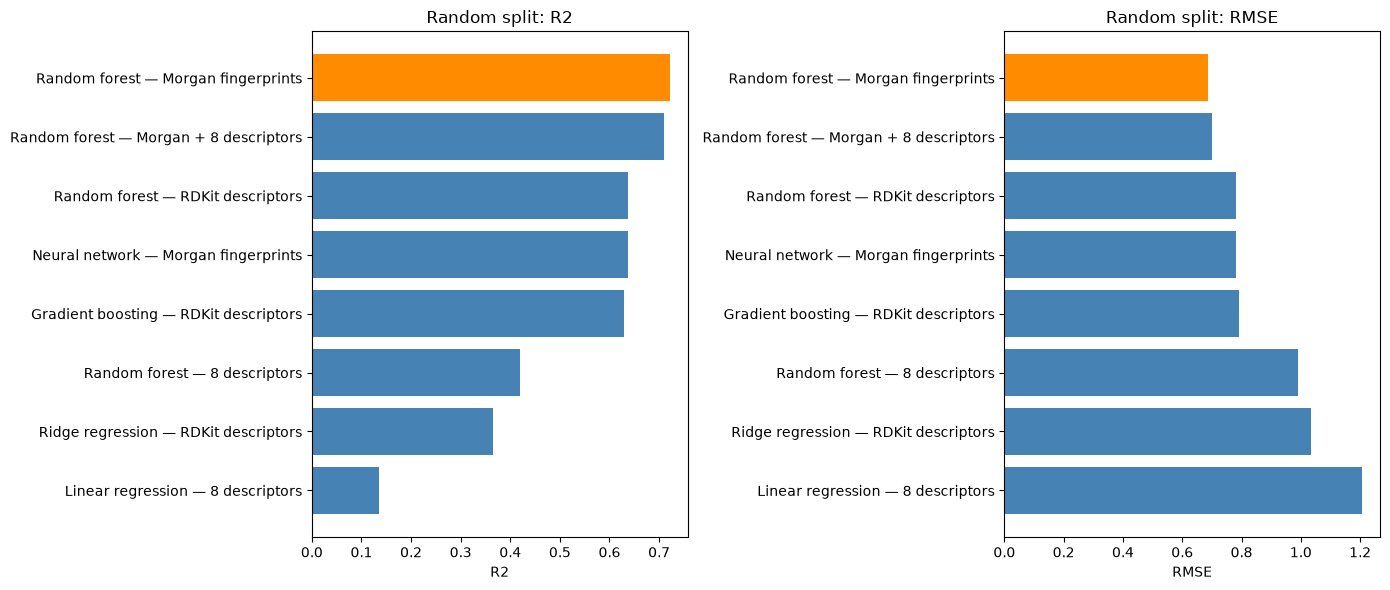

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/model_comparison_random_split.png
Best random-split R2: Random forest — Morgan fingerprints


In [4]:
random_regression = regression[
    regression["Evaluation"] == "Random split"
].sort_values("R2", ascending=False)

display(random_regression[[
    "Model", "Features", "Source", "R2", "RMSE", "MAE"
]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric, higher_is_better in zip(
    axes,
    ["R2", "RMSE"],
    [True, False],
):
    ordered = random_regression.sort_values(
        metric,
        ascending=higher_is_better,
    )
    colors = [
        "darkorange" if model == "Random forest — Morgan fingerprints" else "steelblue"
        for model in ordered["Model"]
    ]
    ax.barh(ordered["Model"], ordered[metric], color=colors)
    ax.set_xlabel(metric)
    ax.set_title(f"Random split: {metric}")

plt.tight_layout()
figure_path = FIGURES_DIR / "model_comparison_random_split.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Best random-split R2:", random_regression.iloc[0]["Model"])


## 5. Scaffold-Split Regression Comparison

Scaffold-split performance is the basis for choosing the model to
move forward. Molecules that share a Bemis–Murcko scaffold stay
together, so the test score measures prediction on new chemical cores.

The model with the highest scaffold-split R² is selected. Root mean
squared error breaks a tie. Five-fold cross-validation and the
full-data refit are excluded from this ranking because they are not
single scaffold holdouts.


,Model,Features,Source,R2,RMSE,MAE
0,Random forest — Morgan fingerprints,Morgan fingerprints,04_model_training.ipynb,0.619,0.784,0.584
1,Random forest — RDKit descriptors,RDKit descriptors,04b_rdkit_qsar_models.ipynb,0.578,0.825,0.628
2,Neural network — Morgan fingerprints,Morgan fingerprints,04_model_training.ipynb,0.500,0.898,0.673
3,Gradient boosting — RDKit descriptors,RDKit descriptors,04b_rdkit_qsar_models.ipynb,0.487,0.909,0.702


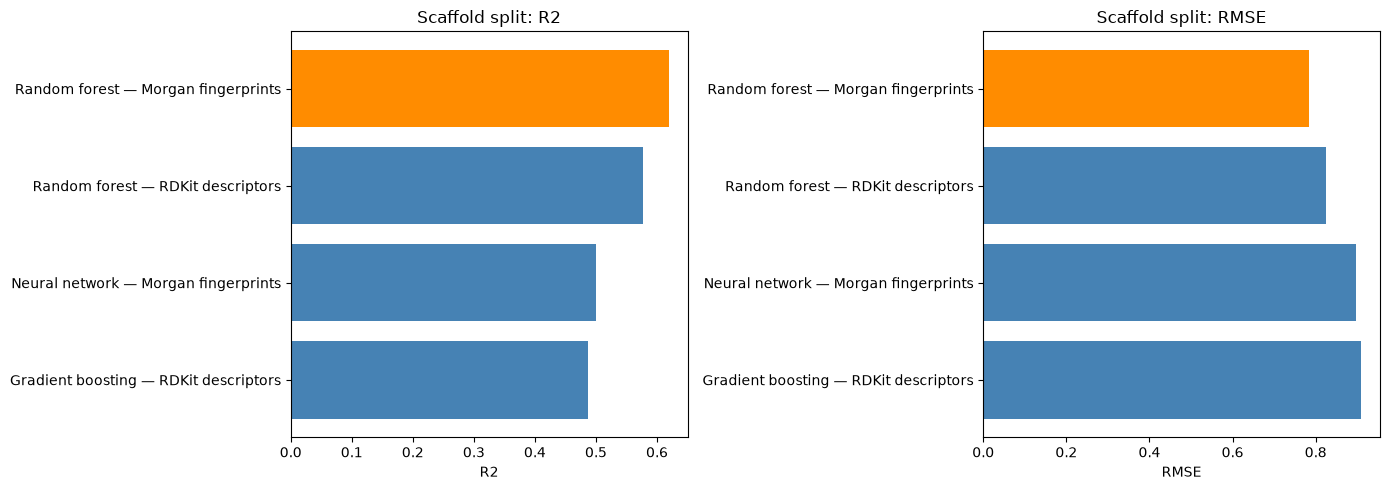

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/model_comparison_scaffold_split.png
Selected regression model: Random forest — Morgan fingerprints
Scaffold-split R2: 0.619
Scaffold-split RMSE: 0.784
Scaffold-split MAE: 0.584


In [5]:
scaffold_regression = regression[
    regression["Evaluation"] == "Scaffold split"
].sort_values(
    ["R2", "RMSE"],
    ascending=[False, True],
).reset_index(drop=True)

display(scaffold_regression[[
    "Model", "Features", "Source", "R2", "RMSE", "MAE"
]].round(3))

selected_regression = scaffold_regression.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, higher_is_better in zip(
    axes,
    ["R2", "RMSE"],
    [True, False],
):
    ordered = scaffold_regression.sort_values(
        metric,
        ascending=higher_is_better,
    )
    colors = [
        "darkorange" if model == selected_regression["Model"] else "steelblue"
        for model in ordered["Model"]
    ]
    ax.barh(ordered["Model"], ordered[metric], color=colors)
    ax.set_xlabel(metric)
    ax.set_title(f"Scaffold split: {metric}")

plt.tight_layout()
figure_path = FIGURES_DIR / "model_comparison_scaffold_split.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Selected regression model:", selected_regression["Model"])
print("Scaffold-split R2:", round(selected_regression["R2"], 3))
print("Scaffold-split RMSE:", round(selected_regression["RMSE"], 3))
print("Scaffold-split MAE:", round(selected_regression["MAE"], 3))


## 6. Active and Inactive Classification

Notebook 04c trained three classifiers on the same Morgan fingerprints
and the same scaffold holdout. Compounds with pIC50 ≥ 6.5
(IC50 ≤ 316.2 nM) are active. Compounds below that threshold are inactive.

Classification metrics are Matthews correlation coefficient, balanced
accuracy, F1, and ROC-AUC. These scores describe a binary label, so
they are not ranked against regression R².


,Model,MCC,Balanced Accuracy,F1,ROC-AUC,Precision,Recall,Accuracy
0,Random forest — Morgan fingerprints,0.648,0.818,0.890,0.905,0.876,0.904,0.848
1,Gradient boosting — Morgan fingerprints,0.594,0.802,0.864,0.893,0.879,0.850,0.819
2,Logistic regression — Morgan fingerprints,0.558,0.785,0.850,0.860,0.869,0.832,0.802


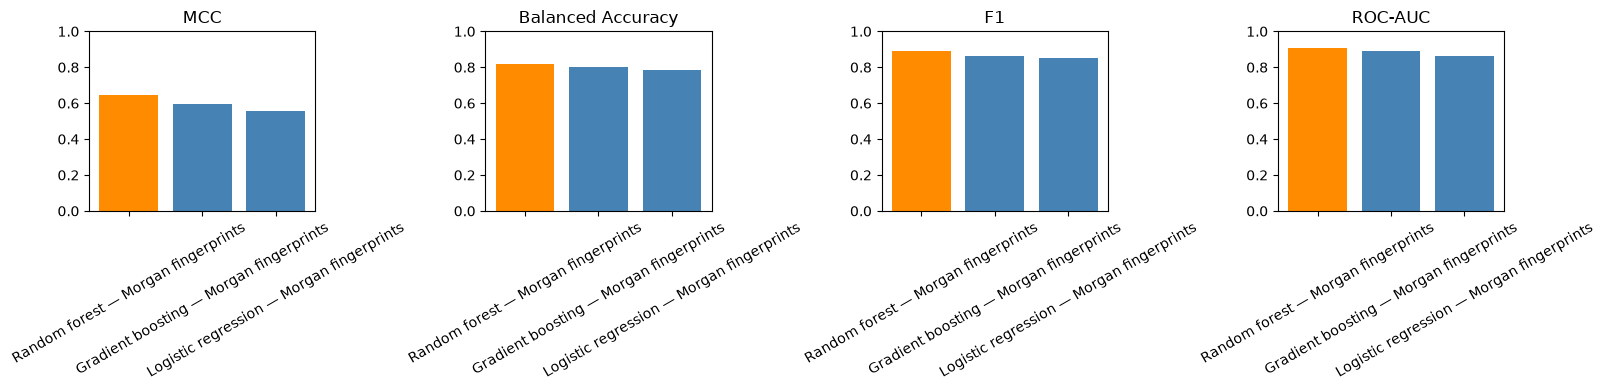

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/model_comparison_classification.png
Best classifier: Random forest — Morgan fingerprints
Scaffold-test MCC: 0.648


In [6]:
classifier_name = {
    "Logistic Regression": "Logistic regression — Morgan fingerprints",
    "Random Forest": "Random forest — Morgan fingerprints",
    "Gradient Boosting": "Gradient boosting — Morgan fingerprints",
}

classifiers = classification.copy()
classifiers["Model"] = classifiers["Model"].map(classifier_name)
classifiers["Algorithm"] = classifiers["Model"].str.split(" — ").str[0]
classifiers["Features"] = "Morgan fingerprints"
classifiers["Task"] = "Classification"
classifiers["Target"] = "Active if pIC50 >= 6.5"
classifiers["Evaluation"] = "Scaffold split"
classifiers["Source"] = "04c_activity_classification.ipynb"

classifiers = classifiers.sort_values(
    ["MCC", "Balanced Accuracy"],
    ascending=False,
).reset_index(drop=True)

selected_classifier = classifiers.iloc[0]

display(classifiers[[
    "Model",
    "MCC",
    "Balanced Accuracy",
    "F1",
    "ROC-AUC",
    "Precision",
    "Recall",
    "Accuracy",
]].round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, metric in zip(axes, ["MCC", "Balanced Accuracy", "F1", "ROC-AUC"]):
    colors = [
        "darkorange" if model == selected_classifier["Model"] else "steelblue"
        for model in classifiers["Model"]
    ]
    ax.bar(classifiers["Model"], classifiers[metric], color=colors)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")

plt.tight_layout()
figure_path = FIGURES_DIR / "model_comparison_classification.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)
print("Best classifier:", selected_classifier["Model"])
print("Scaffold-test MCC:", round(selected_classifier["MCC"], 3))


## 7. Model Selected for the Next Stage

Virtual screening ranks external compounds by predicted potency, and
molecular docking then evaluates the highest-ranked molecules. That
workflow needs a continuous pIC50 prediction.

The scaffold-split regression comparison selects the Morgan fingerprint
random forest. Its scaffold-split R² is 0.619, with RMSE 0.784 and
MAE 0.584. The next scaffold-split model, the RDKit-descriptor random
forest, reaches R² 0.578. The Morgan fingerprint neural network reaches
R² 0.500. The same random forest also leads the random-split comparison
(R² 0.721) and is stable under five-fold cross-validation
(R² 0.711 ± 0.012).

Notebook 05 retrained this model on all 10,381 compounds and saved
`results/models/egfr_morgan_rf_final.joblib`. That file is the model
to move forward with for candidate screening and docking.

The strongest classifier is also a Morgan fingerprint random forest
(MCC 0.648 on the scaffold holdout). It remains the model to use when
the question is the binary active/inactive label from notebook 04c.
Screening continues to use the continuous pIC50 model, because compounds
above the activity threshold still differ in potency.


In [7]:
forward_model = {
    "Selected model": "Random forest — Morgan fingerprints",
    "Task": "Regression",
    "Target": "pIC50",
    "Features": "Morgan fingerprints (radius 2, 2048 bits)",
    "Selection rule": "Highest scaffold-split R2",
    "Scaffold-split R2": round(float(selected_regression["R2"]), 3),
    "Scaffold-split RMSE": round(float(selected_regression["RMSE"]), 3),
    "Scaffold-split MAE": round(float(selected_regression["MAE"]), 3),
    "Random-split R2": round(float(
        random_regression.loc[
            random_regression["Model"] == "Random forest — Morgan fingerprints",
            "R2",
        ].iloc[0]
    ), 3),
    "Deployed file": "results/models/egfr_morgan_rf_final.joblib",
    "Best classifier": selected_classifier["Model"],
    "Classifier MCC": round(float(selected_classifier["MCC"]), 3),
}

deployed_path = MODELS_DIR / "egfr_morgan_rf_final.joblib"
print("Deployed model exists:", deployed_path.exists())
print("Deployed model path:", deployed_path)

selection = pd.DataFrame([forward_model])
display(selection.T.rename(columns={0: "Decision"}))

assert selected_regression["Model"] == "Random forest — Morgan fingerprints"
assert selected_classifier["Model"].startswith("Random forest")
print("Model to move forward with: Morgan fingerprint random forest regressor.")


Deployed model exists: True
Deployed model path: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/models/egfr_morgan_rf_final.joblib


,Decision
Selected model,Random forest — Morgan fingerprints
Task,Regression
Target,pIC50
Features,"Morgan fingerprints (radius 2, 2048 bits)"
Selection rule,Highest scaffold-split R2
Scaffold-split R2,0.619
Scaffold-split RMSE,0.784
Scaffold-split MAE,0.584
Random-split R2,0.721
Deployed file,results/models/egfr_morgan_rf_final.joblib


Model to move forward with: Morgan fingerprint random forest regressor.


## 8. Comparison Export

The regression ledger, the classification results, and the model
selection are saved under `results/` so later notebooks can reload the
decision without reconstructing the tables.


In [8]:
regression_path = RESULTS_DIR / "all_regression_model_comparison.csv"
classification_path = RESULTS_DIR / "all_classification_model_comparison.csv"
selection_path = RESULTS_DIR / "selected_model.csv"

regression_ledger.to_csv(regression_path, index=False)
classifiers.to_csv(classification_path, index=False)
selection.to_csv(selection_path, index=False)

print("Regression comparison:", regression_path)
print("Classification comparison:", classification_path)
print("Selected model:", selection_path)
print("Move forward with:", forward_model["Deployed file"])


Regression comparison: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/all_regression_model_comparison.csv
Classification comparison: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/all_classification_model_comparison.csv
Selected model: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/results/selected_model.csv
Move forward with: results/models/egfr_morgan_rf_final.joblib
